# Coding Regression Discontinuity: Sharp and Fuzzy

**DS-UA 201: Causal Inference — Lab Notes**

We've covered the theory. This notebook recaps it, then shows **how to code an RDD step by step**. Along the way we write two small functions, `binscatter()` and `local_linear()`, and reuse them for everything.

1. Recap of sharp and fuzzy RDD.
2. Coding a sharp RDD (scholarship example).
3. Coding a fuzzy RDD (summer school example).
4. Recap of both frameworks, with a code template.

---
## 1. Recap

### 1.1 Sharp RDD

**The idea.** Lots of rules use a cutoff: score 90+ and you get an A, get 50%+ of the vote and you win. People **just above** and **just below** a cutoff are treated differently, but are otherwise almost identical. Comparing them is like a mini natural experiment right at the cutoff.

**The setup.** Three ingredients:

- A **running variable** $R$, e.g. a test score.
- A **cutoff** $c$, e.g. 90.
- A treatment $S$ that is **completely determined** by the cutoff:

$$S = \begin{cases} 1 & \text{if } R \geq c \\ 0 & \text{if } R < c \end{cases}$$

"Sharp" means *everyone* above the cutoff is treated and *no one* below it is.

**Why we need it.** Usually treated and untreated people differ in ways we can't see ($S \not\perp U$). A students are smarter on average, election winners are more popular. Near the cutoff, though, whether you land at 89.9 or 90.1 is basically luck.

**The key assumption: smoothness.** Average potential outcomes change *smoothly* as $R$ changes:

$$E[Y(S=1,U)\mid R=r] \text{ and } E[Y(S=0,U)\mid R=r] \text{ are continuous at } r=c$$

In plain words: **nothing jumps at the cutoff except treatment.** Students' characteristics can (and do) change with their score, just not suddenly at 90. So if the outcome jumps at the cutoff, the treatment must have caused it.

**What we estimate.** The effect for people **at the cutoff**:

$$\tau_{\text{sharp}} = E[Y(S=1,U) - Y(S=0,U) \mid R=c]$$

It says nothing about people far from the cutoff (e.g. what an A would do for a student who scored 40).

**Bandwidth.** We can't only use people *exactly* at the cutoff; there are too few. So we use everyone within a **bandwidth** $b$ of it, i.e. $R$ between $c-b$ and $c+b$.

| | Small bandwidth | Large bandwidth |
|---|---|---|
| Comparison | Very similar people on each side | Less similar people |
| Sample size | Small | Large |
| Result | Less bias, more noise | More bias, less noise |

The practical solution is to **try several bandwidths**. If the estimates are similar, the result is convincing.

**Local linear regression.** Outcomes usually trend with the running variable (higher scores, better outcomes), so we don't just compare averages on each side. Instead we fit a straight line on each side within the bandwidth:

$$Y = \alpha_0 + \alpha_1 S + \alpha_2 (R - c) + \alpha_3\, S \cdot (R - c)$$

| Coefficient | Meaning |
|---|---|
| $\alpha_0$ | Predicted outcome just below the cutoff |
| $\alpha_1$ | **The jump at the cutoff: our estimate** |
| $\alpha_2$ | Slope on the left side |
| $\alpha_2 + \alpha_3$ | Slope on the right side |

Two tricks make this work:

- **Centring:** we use $R - c$ (distance from the cutoff) instead of $R$. Then $R - c = 0$ at the cutoff, so $\alpha_1$ is the gap *exactly at* the cutoff.
- **The interaction** $S \cdot (R-c)$ lets the slope be different on each side.

**Checking the assumption.** Smoothness is about things we can't see, so we can't test it directly. But we can check two things it implies:

1. **Covariates are smooth.** Things fixed *before* treatment (like high school GPA) shouldn't jump at the cutoff. Test this by running the same regression with the covariate as the outcome. We want no jump.
2. **No manipulation.** If people can push themselves just over the cutoff, those just above aren't comparable to those just below. You'd see **bunching**: too many people just above the cutoff. So we count observations on each side.

### 1.2 Fuzzy RDD

**The idea.** Sometimes crossing the cutoff doesn't *guarantee* treatment; it just makes it **more likely**. Example: scoring above a university's SAT cutoff raises your chance of admission, but grades and extracurriculars matter too. So:

$$P(S=1 \mid R) \text{ jumps at the cutoff, but not from 0 to 1}$$

**Why the sharp approach fails.** If only some people respond to the cutoff, the jump in $Y$ is **diluted**. Say crossing the cutoff raises the chance of treatment by 30 percentage points. Then only 30% of people actually changed treatment, so the jump in $Y$ is only about 30% of the real effect.

**The fix: treat it as IV.** Being on the "treated" side of the cutoff is our **instrument**:

$$Z = \begin{cases} 1 & \text{if } R \geq c \\ 0 & \text{if } R < c \end{cases}$$

Near the cutoff, $Z$ is as good as random, and it shifts treatment. That's exactly what an instrument needs.

**The same compliance types as IV:**

| Type | Behaviour |
|---|---|
| Compliers | Treated only if above the cutoff |
| Always-takers | Treated either way |
| Never-takers | Never treated |
| Defiers | Treated only if *below* (ruled out by monotonicity) |

**Assumptions.** Smoothness (as in sharp), plus the IV assumptions near the cutoff:

- **Relevance:** the cutoff actually changes treatment for some people. Check: the jump in $P(S=1)$ is not zero.
- **Monotonicity:** crossing the cutoff never makes anyone *less* likely to be treated.
- **Exogeneity:** being just above vs. just below is as good as random.

**What we estimate.** Divide the two jumps, exactly like the Wald estimator:

$$\tau_{\text{fuzzy}} = \frac{\text{jump in } Y \text{ at the cutoff}}{\text{jump in } P(S=1) \text{ at the cutoff}} = \frac{\text{reduced form}}{\text{first stage}}$$

This is the effect for **compliers at the cutoff** (a LATE):

$$E[Y(S=1,U) - Y(S=0,U) \mid R=c,\ \text{complier}]$$

Dividing by the first stage "undoes" the dilution. A sharp RDD is just the special case where the first stage is 1.

---
## 2. Coding a sharp RDD

**The question.** A university gives a scholarship to every applicant who scores **80 or above** on its entrance exam. Does the scholarship raise first-year college GPA?

| RDD piece | Here |
|---|---|
| Running variable $R$ | Entrance exam score |
| Cutoff $c$ | 80 |
| Treatment $S$ | Got the scholarship |
| Outcome $Y$ | First-year college GPA |

We simulate the data so we know the answer: **the true effect is +0.15 GPA points.**

### Step 0: imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

### Step 1: get the data

With real data, this step is just `df = pd.read_csv("file.csv")`. Here we make fake data.

In [2]:
rng = np.random.default_rng(3)
n = 10_000

ability = rng.normal(0, 1, n)
score = (78 + 8 * ability + 7 * rng.normal(0, 1, n)).round(1)
hs_gpa = (3.0 + 0.3 * ability + rng.normal(0, 0.3, n)).round(2)
college_gpa = 2.9 + 0.03 * (score - 80) + 0.2 * ability + 0.15 * (score >= 80) + rng.normal(0, 0.35, n)

df = pd.DataFrame({"score": score, "hs_gpa": hs_gpa, "college_gpa": college_gpa})
df.head()

,score,hs_gpa,college_gpa
0,94.6,4.27,4.711804
1,52.1,2.47,1.872168
2,81.3,3.06,3.127495
3,81.9,2.90,2.674012
4,74.5,2.01,3.639985


**The code**

- `ability` is a hidden trait: it raises both exam scores and college GPA. That's why simply comparing scholarship holders with everyone else would be biased. We leave it out of `df`, because in real life you can't observe it.
- `college_gpa` rises smoothly with score (`0.03 * (score - 80)`), plus **0.15 for anyone who scored 80 or more**. That 0.15 is the effect we want to find.
- `hs_gpa` is decided *before* the exam. We'll use it later as a check.

### Step 2: create the RDD variables

Every RDD needs the same two columns:

In [3]:
CUTOFF = 80

df["Rminusc"] = df["score"] - CUTOFF
df["scholarship"] = (df["score"] >= CUTOFF).astype(int)

df.head()

,score,hs_gpa,college_gpa,Rminusc,scholarship
0,94.6,4.27,4.711804,14.6,1
1,52.1,2.47,1.872168,-27.9,0
2,81.3,3.06,3.127495,1.3,1
3,81.9,2.90,2.674012,1.9,1
4,74.5,2.01,3.639985,-5.5,0


**The code**

- `Rminusc` is the **distance from the cutoff**: a score of 83 becomes 3, and 77 becomes −3.
- `df["score"] >= CUTOFF` gives `True` or `False` for each student, and `.astype(int)` turns that into 1 or 0. This is the scholarship (treatment) column.

### Step 3: plot it

Always look at the data before running regressions. A scatter of 10,000 dots is unreadable, so we make a **bin scatter**: group scores into 1-point bins and plot the **average** in each bin.

We'll make this plot several times, so we write a function:

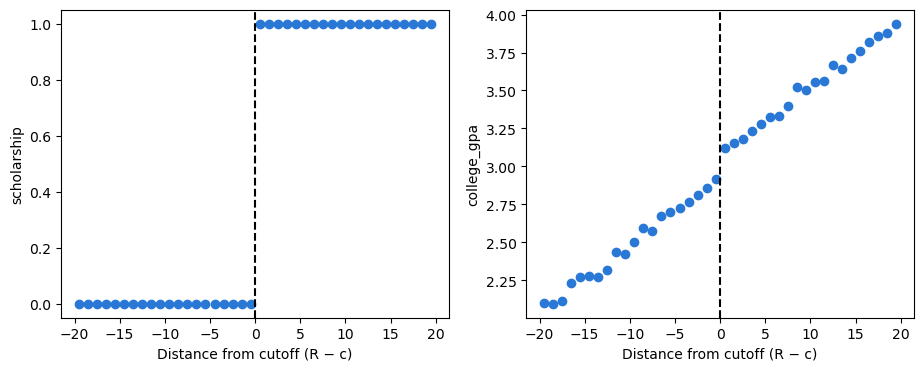

In [4]:
def binscatter(data, y, ax):
    near = data[data["Rminusc"].abs() < 20]
    bins = np.floor(near["Rminusc"]) + 0.5
    averages = near.groupby(bins)[y].mean()

    ax.scatter(averages.index, averages.values, color="#2a78d6")
    ax.axvline(0, color="black", linestyle="--")
    ax.set(xlabel="Distance from cutoff (R − c)", ylabel=y)


fig, axes = plt.subplots(1, 2, figsize=(11, 4))
binscatter(df, "scholarship", axes[0])
binscatter(df, "college_gpa", axes[1])
plt.show()

**The code**

- `near = ...` keeps students within 20 points of the cutoff.
- `np.floor(near["Rminusc"]) + 0.5` puts each student into a 1-point bin. `np.floor` rounds **down** (2.7 → 2, −0.3 → −1), and `+ 0.5` labels the bin by its middle (2.5, −0.5). Rounding down means no bin ever mixes students from both sides of the cutoff.
- `groupby(bins)[y].mean()` averages `y` within each bin. Those averages are the dots.
- `y` is an input, so the same function can plot any column.
- `ax.axvline(0, ...)` draws a dashed line at the cutoff.

**Reading the plots.** Left: the scholarship jumps from 0 to 1 at the cutoff, so the design is sharp. Right: GPA climbs steadily with score, with a clear **step up at the cutoff**. That step is what we estimate next.

### Step 4: estimate the jump

First, written out in full for one bandwidth ($b = 5$, so scores 75 to 85):

In [5]:
b = 5
window = df[df["Rminusc"].abs() < b].copy()
window["SRminusc"] = window["scholarship"] * window["Rminusc"]

fit = smf.ols("college_gpa ~ scholarship + Rminusc + SRminusc", data=window).fit(cov_type="HC0")
print(fit.params)

Intercept      2.937653
scholarship    0.155814
Rminusc        0.048175
SRminusc      -0.007479
dtype: float64


**The code**

1. `window = ...` keeps only students within 5 points of the cutoff. This is the bandwidth.
2. `SRminusc` is the interaction $S \cdot (R - c)$, so each side gets its own slope.
3. The formula `college_gpa ~ scholarship + Rminusc + SRminusc` is our local linear regression: $Y = \alpha_0 + \alpha_1 S + \alpha_2(R-c) + \alpha_3 S(R-c)$.
4. `cov_type="HC0"` gives robust standard errors.

**Reading the output.** The `scholarship` coefficient, about **0.16**, is the jump at the cutoff: our estimate of the effect (truth: 0.15). The other coefficients are just the intercept and slopes.

### Step 5: make it a function

We'll run this regression many more times, so we turn Step 4 into a function:

In [6]:
def local_linear(data, y, b, d):
    window = data[data["Rminusc"].abs() < b].copy()
    window["DRminusc"] = window[d] * window["Rminusc"]
    return smf.ols(f"{y} ~ {d} + Rminusc + DRminusc", data=window).fit(cov_type="HC0")


local_linear(df, "college_gpa", b=5, d="scholarship").params["scholarship"]

0.15581445447078415

**The code**

It's the same as Step 4 with two inputs swapped in:

- `y` is the outcome column.
- `d` is the cutoff column (here `"scholarship"`).

The f-string `f"{y} ~ {d} + Rminusc + DRminusc"` fills them into the formula. The last line confirms we get the same answer as Step 4.

### Step 6: try several bandwidths

In [7]:
for b in [2, 5, 10, 20]:
    fit = local_linear(df, "college_gpa", b, d="scholarship")
    print(f"b = {b:>2}:  estimate = {fit.params['scholarship']:.3f}   SE = {fit.bse['scholarship']:.3f}   n = {int(fit.nobs)}")

b =  2:  estimate = 0.155   SE = 0.042   n = 1426
b =  5:  estimate = 0.156   SE = 0.026   n = 3525
b = 10:  estimate = 0.154   SE = 0.018   n = 6375
b = 20:  estimate = 0.151   SE = 0.014   n = 9375


**The code**

A loop over bandwidths, calling our function each time. `.params` gives the estimate, `.bse` the standard error, and `.nobs` the number of students used.

**Reading the output.** Every bandwidth gives about **0.15**, and the standard error shrinks as we use more students. Stable estimates across bandwidths are exactly what we want to see.

### Step 7: check the design

Thanks to our function, each check is a single line.

In [8]:
placebo = local_linear(df, "hs_gpa", b=5, d="scholarship")
print(f"Jump in high school GPA: {placebo.params['scholarship']:.3f}  (p = {placebo.pvalues['scholarship']:.2f})")

just_below = ((df["Rminusc"] >= -1) & (df["Rminusc"] < 0)).sum()
just_above = ((df["Rminusc"] >= 0) & (df["Rminusc"] < 1)).sum()
p = stats.binomtest(just_above, just_below + just_above).pvalue
print(f"Students just below: {just_below}, just above: {just_above}  (p = {p:.2f})")

Jump in high school GPA: 0.000  (p = 0.99)
Students just below: 365, just above: 344  (p = 0.45)


**The code**

- **Covariate check:** the same function, with `"hs_gpa"` as the outcome. High school GPA was set before the exam, so it shouldn't jump.
- **Manipulation check:** count students scoring 79–80 and 80–81. Without manipulation, landing on either side is a coin flip. `stats.binomtest` tests whether the split is consistent with 50/50.

**Reading the output.** No jump in high school GPA (large p-value) and a balanced split (large p-value). The design passes both checks.

---
## 3. Coding a fuzzy RDD

**The question.** A school *recommends* summer school to every student scoring **below 60** on a test. Recommended students are much more likely to go, but it's optional: some skip it, and some students above 60 go anyway. Does summer school raise next year's score?

| RDD piece | Here |
|---|---|
| Running variable $R$ | This year's test score |
| Cutoff $c$ | 60 |
| Instrument $Z$ | Scored below 60 (recommended) |
| Treatment $S$ | Actually went to summer school |
| Outcome $Y$ | Next year's test score |

Note that the treated side is **below** the cutoff here. That's fine: we just define $Z = 1$ for scores below 60.

**The true effect for compliers is +5 points.**

### Step 1: get the data

In [9]:
rng = np.random.default_rng(60)
n = 20_000

ability = rng.normal(0, 1, n)
score = (65 + 10 * ability + 8 * rng.normal(0, 1, n)).round(1)

u = rng.uniform(size=n)
complier = u < 0.30
always = (u >= 0.30) & (u < 0.40)
attend = (always | (complier & (score < 60))).astype(int)

next_score = 65 + 0.7 * (score - 60) + 4 * ability + attend * np.where(complier, 5, 3) + rng.normal(0, 8, n)

ss = pd.DataFrame({"score": score, "attend": attend, "next_score": next_score})
ss.head()

,score,attend,next_score
0,39.5,0,47.322764
1,42.2,1,55.555252
2,69.8,0,81.648626
3,57.3,1,62.479739
4,46.3,1,64.134959


**The code**

- `u` is a random number per student that sets their type: 30% **compliers** (attend only if recommended), 10% **always-takers** (attend anyway), and the rest **never-takers**.
- `attend` is 1 for always-takers, and for compliers who scored below 60. So the cutoff changes attendance only for compliers. That's what makes it fuzzy.
- In `next_score`, summer school adds **5 points for compliers** (3 for always-takers).

### Step 2: create the RDD variables

In [10]:
CUTOFF = 60

ss["Rminusc"] = ss["score"] - CUTOFF
ss["z"] = (ss["score"] < CUTOFF).astype(int)

**The code**

Same as before, with one change: `<` instead of `>=`, because the recommendation goes to students **below** 60. `z` is our instrument.

### Step 3: plot it

Our `binscatter()` function works without any changes:

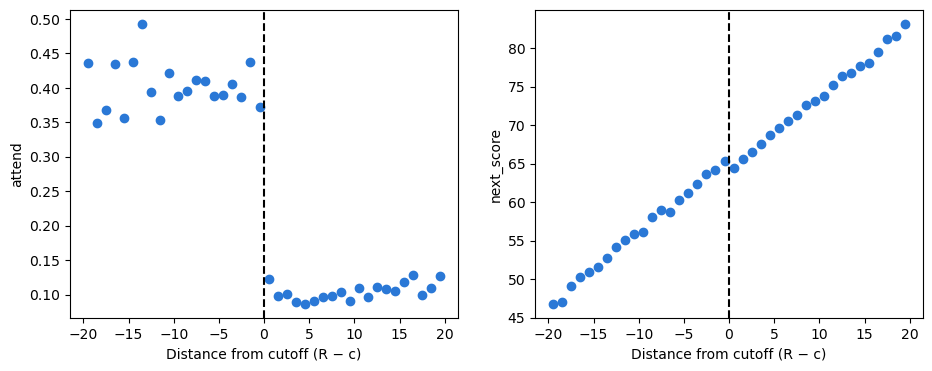

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
binscatter(ss, "attend", axes[0])
binscatter(ss, "next_score", axes[1])
plt.show()

**Reading the plots.**

- **Left (first stage):** about 40% attend just below the cutoff, versus about 10% just above. That's a jump of about 30 percentage points, but not 0 → 1, so the design is fuzzy.
- **Right (outcome):** you can barely see a jump. That's expected: only 30% of students changed what they did, so the jump in scores is diluted. This is why we need to divide by the first stage.

**Why not just compare attendees with non-attendees?**

In [12]:
naive = ss.loc[ss["attend"] == 1, "next_score"].mean() - ss.loc[ss["attend"] == 0, "next_score"].mean()
print(f"Naive comparison: {naive:.2f} points")

Naive comparison: -4.54 points


The naive comparison says summer school **lowers** scores by about 4.5 points, when it actually raises them by 5. Attendees are mostly weaker students, so of course they score lower next year.

### Step 4: first stage ÷ reduced form

A fuzzy RDD is **two sharp RDDs and a division**, so we just reuse `local_linear()`:

In [13]:
b = 10
first_stage = local_linear(ss, "attend", b, d="z")
reduced_form = local_linear(ss, "next_score", b, d="z")

print(f"First stage  (jump in attendance): {first_stage.params['z']:.3f}")
print(f"Reduced form (jump in next score): {reduced_form.params['z']:.3f}")
print(f"Fuzzy RDD = reduced form / first stage: {reduced_form.params['z'] / first_stage.params['z']:.2f}")

First stage  (jump in attendance): 0.299
Reduced form (jump in next score): 1.661
Fuzzy RDD = reduced form / first stage: 5.56


**The code**

- **First stage:** an RDD with **attendance** as the outcome. The jump (≈ 0.30) says being recommended raises attendance by 30 percentage points.
- **Reduced form:** an RDD with **next year's score** as the outcome. The jump (≈ 1.7) is the effect of being *recommended*, diluted because most students didn't change.
- **Divide:** 1.7 / 0.30 ≈ **5.6**, close to the true 5.

### Step 5: get the standard error with IV

The division gives the right estimate, but not a standard error. For that, we run it as a single IV regression:

In [14]:
%pip install -q linearmodels

Note: you may need to restart the kernel to use updated packages.


In [15]:
from linearmodels.iv import IV2SLS

window = ss[ss["Rminusc"].abs() < b].copy()
window["ZRminusc"] = window["z"] * window["Rminusc"]

iv = IV2SLS.from_formula("next_score ~ 1 + Rminusc + ZRminusc + [attend ~ z]", data=window).fit(cov_type="robust")
print(iv.summary.tables[1])

                             Parameter Estimates                              
            Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
------------------------------------------------------------------------------
Intercept      63.569     0.3058     207.85     0.0000      62.970      64.169
Rminusc        0.9880     0.0394     25.069     0.0000      0.9108      1.0653
ZRminusc      -0.0126     0.0584    -0.2155     0.8294     -0.1270      0.1019
attend         5.5563     1.0828     5.1313     0.0000      3.4340      7.6786


**The code**

- `window` and `ZRminusc` are the same bandwidth and interaction as before. `IV2SLS` needs them as columns.
- `[attend ~ z]` means "attendance, instrumented by being below the cutoff".
- `1 + Rminusc + ZRminusc` are the intercept and slopes, as in the sharp RDD.
- The interaction uses `z`, not `attend`, because the controls can only involve the cutoff, not the treatment we're instrumenting.

**Reading the output.** The `attend` coefficient matches Step 4 (≈ 5.6), now with a standard error and confidence interval. **Interpretation:** for students near 60 who go to summer school *only because* they were recommended, it raises next year's score by about 5–6 points.

---
## 4. Recap: the two frameworks

| | Sharp RDD | Fuzzy RDD |
|---|---|---|
| **What the cutoff does** | Decides treatment completely (0 → 1) | Makes treatment more likely |
| **Cutoff variable** | Treatment itself, $S$ | An instrument, $Z$ |
| **Assumptions** | Smoothness at the cutoff | Smoothness, plus relevance, monotonicity and exogeneity |
| **Estimate** | The jump in $Y$ | Jump in $Y$ ÷ jump in $P(S=1)$ |
| **Effect for** | People at the cutoff | Compliers at the cutoff |
| **Checks** | Covariates smooth, no bunching | Same, plus a clear first-stage jump |

### Code template

```python
# 1. Set up
df["Rminusc"] = df["running_var"] - CUTOFF
df["D"] = (df["running_var"] >= CUTOFF).astype(int)     # use < if treatment is below

# 2. Plot
binscatter(df, "treatment", ax1)
binscatter(df, "outcome", ax2)

# 3a. Sharp: the coefficient on D is the effect
local_linear(df, "outcome", b, d="D").params["D"]

# 3b. Fuzzy: divide the two jumps (use IV2SLS for standard errors)
local_linear(df, "outcome", b, d="D").params["D"] / local_linear(df, "treatment", b, d="D").params["D"]

# 4. Repeat with several bandwidths
# 5. Checks: local_linear on a covariate, and count observations just above vs. below the cutoff
```